In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns',None)

In [2]:
df_train=pd.read_parquet('training_project_1.parquet')
df_test=pd.read_parquet('testing_project_1.parquet')

In [3]:
df_train.shape

(175341, 36)

In [4]:
df_test.shape

(82332, 36)

In [5]:
df_train.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,8495.365234,0,0,24.295601,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,503571.312500,2,17,49.915001,15.432865,61.426933,1387.778320,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,60929.230469,1,6,231.875565,102.737206,17179.585938,11420.925781,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,1,1,0,0,0,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,3358.622070,1,3,152.876541,90.235725,259.080170,4991.784668,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,1,1,0,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,3987.059814,2,1,47.750332,75.659599,2415.837646,115.806999,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,2,1,0,0,0,0,Normal,0


In [6]:
df_train.label.value_counts()

label
1    119341
0     56000
Name: count, dtype: int64

In [7]:
df_train.columns

Index(['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt',
       'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt',
       'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports',
       'attack_cat', 'label'],
      dtype='object')

In [8]:
df_train.columns.shape

(36,)

In [9]:
df_train.describe()

,dur,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,175341.000000,1.753410e+05,1.753410e+05,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,175341.000000,175341.000000,1.753410e+05,1.753410e+05,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,95406.179688,7.345403e+07,6.712055e+05,4.953000,6.948010,985.976807,88.216301,4.976255e+03,604.353821,116.257339,9.692504e+08,9.688770e+08,115.013625,0.041396,0.021020,0.020375,136.751769,124.173382,0.105982,2.144292e+03,5.383538,4.206255,0.014948,0.014948,0.133066,0.015752,0.680622
std,6.483313,136.887597,110.258271,1.747656e+05,1.436542e+05,165417.671875,1.883701e+08,2.423637e+06,66.005059,52.732999,7244.195801,985.741211,4.498317e+04,4056.382568,127.001024,1.355264e+09,1.354000e+09,126.886530,0.079340,0.043349,0.040521,204.677360,258.317056,0.776911,5.420797e+04,8.047104,5.783585,0.126048,0.126048,0.701208,0.124516,0.466237
min,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,28.000000,0.000000,0.000000,0.000000e+00,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,32.786140,1.305334e+04,0.000000e+00,0.000000,0.000000,0.008000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,57.000000,0.000000,0.000000,0.000000e+00,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3225.806641,8.796748e+05,1.447023e+03,0.000000,0.000000,0.279733,0.006000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,73.000000,44.000000,0.000000,0.000000e+00,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,125000.000000,8.888889e+07,2.784487e+04,3.000000,2.000000,55.156895,51.053001,2.513295e+03,114.990623,255.000000,1.916651e+09,1.913675e+09,255.000000,0.065481,0.023268,0.038906,100.000000,89.000000,0.000000,0.000000e+00,5.000000,3.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1000000.000000,5.988000e+09,2.242273e+07,4803.000000,5484.000000,84371.492188,56716.824219,1.460480e+06,289388.281250,255.000000,4.294959e+09,4.294882e+09,255.000000,2.518893,2.100352,1.520884,1504.000000,1458.000000,172.000000,6.558056e+06,51.000000,46.000000,4.000000,4.000000,30.000000,1.000000,1.000000


In [10]:
df_train.dtypes

dur                   float32
proto                category
service              category
state                category
spkts                   int16
dpkts                   int16
sbytes                  int32
dbytes                  int32
rate                  float32
sload                 float32
dload                 float32
sloss                   int16
dloss                   int16
sinpkt                float32
dinpkt                float32
sjit                  float32
djit                  float32
swin                    int16
stcpb                   int64
dtcpb                   int64
dwin                    int16
tcprtt                float32
synack                float32
ackdat                float32
smean                   int16
dmean                   int16
trans_depth             int16
response_body_len       int32
ct_src_dport_ltm         int8
ct_dst_sport_ltm         int8
is_ftp_login             int8
ct_ftp_cmd               int8
ct_flw_http_mthd         int8
is_sm_ips_

In [11]:
df_train.state.value_counts()

state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64

In [12]:
df_train.proto.value_counts()

proto
tcp     79946
udp     63283
unas    12084
arp      2859
ospf     2595
        ...  
hmp        98
rdp        98
igmp       18
icmp       15
rtp         1
Name: count, Length: 133, dtype: int64

In [13]:
df_train.service.value_counts()

service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64

In [14]:
df_train.attack_cat.value_counts()

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

In [15]:
df_train.isna().sum()

dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
is_sm_ips_ports      0
attack_cat           0
label                0
dtype: int64

In [16]:
df_train.drop(['attack_cat'],axis=1,inplace=True)

In [17]:
df_train

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,1.415894e+04,8495.365234,0,0,24.295601,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,1,0,0,0,0,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8.395112e+03,503571.312500,2,17,49.915001,15.432865,61.426933,1387.778320,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,1,1,0,0,0,0,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1.572272e+03,60929.230469,1,6,231.875565,102.737206,17179.585938,11420.925781,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,1,1,0,0,0,0,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2.740179e+03,3358.622070,1,3,152.876541,90.235725,259.080170,4991.784668,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,1,1,0,0,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8.561499e+03,3987.059814,2,1,47.750332,75.659599,2415.837646,115.806999,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,2,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175336,0.000009,udp,dns,INT,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,24,13,0,0,0,0,1
175337,0.505762,tcp,-,FIN,10,8,620,354,33.612648,8.826286e+03,4903.492188,2,1,54.400112,66.980568,3721.068848,120.177727,255,3518776216,3453092386,255,0.099440,0.036895,0.062545,62,44,0,0,1,1,0,0,0,0,1
175338,0.000009,udp,dns,INT,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,3,3,0,0,0,0,1
175339,0.000009,udp,dns,INT,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,30,14,0,0,0,0,1


In [18]:
df_train.loc[df_train.duplicated()]

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,label
58,0.000000,arp,-,INT,1,0,46,0,0.000000,0.000000e+00,0.0000,0,0,0.000000,0.000,0.0,0.0,0,0,0,0,0.0,0.0,0.0,46,0,0,0,1,1,0,0,0,1,0
66,50.004398,ospf,-,INT,6,0,384,0,0.099991,5.119550e+01,0.0000,0,0,10000.879883,0.000,0.0,0.0,0,0,0,0,0.0,0.0,0.0,64,0,0,0,1,2,0,0,0,0,0
169,0.000011,udp,-,INT,2,0,2120,0,90909.093750,7.709091e+08,0.0000,0,0,0.011000,0.000,0.0,0.0,0,0,0,0,0.0,0.0,0.0,1060,0,0,0,7,2,0,0,0,0,0
214,0.001146,udp,dns,CON,2,2,146,178,2617.801025,5.095986e+05,621291.4375,0,0,0.009000,0.006,0.0,0.0,0,0,0,0,0.0,0.0,0.0,73,89,0,0,2,2,0,0,0,0,0
313,0.001098,udp,dns,CON,2,2,132,164,2732.240479,4.808743e+05,597449.9375,0,0,0.010000,0.008,0.0,0.0,0,0,0,0,0.0,0.0,0.0,66,82,0,0,3,2,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175335,0.000006,udp,dns,INT,2,0,114,0,166666.656250,7.600000e+07,0.0000,0,0,0.006000,0.000,0.0,0.0,0,0,0,0,0.0,0.0,0.0,57,0,0,0,33,17,0,0,0,0,1
175336,0.000009,udp,dns,INT,2,0,114,0,111111.109375,5.066666e+07,0.0000,0,0,0.009000,0.000,0.0,0.0,0,0,0,0,0.0,0.0,0.0,57,0,0,0,24,13,0,0,0,0,1
175338,0.000009,udp,dns,INT,2,0,114,0,111111.109375,5.066666e+07,0.0000,0,0,0.009000,0.000,0.0,0.0,0,0,0,0,0.0,0.0,0.0,57,0,0,0,3,3,0,0,0,0,1
175339,0.000009,udp,dns,INT,2,0,114,0,111111.109375,5.066666e+07,0.0000,0,0,0.009000,0.000,0.0,0.0,0,0,0,0,0.0,0.0,0.0,57,0,0,0,30,14,0,0,0,0,1


In [19]:
df_train

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,1.415894e+04,8495.365234,0,0,24.295601,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,1,0,0,0,0,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8.395112e+03,503571.312500,2,17,49.915001,15.432865,61.426933,1387.778320,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,1,1,0,0,0,0,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1.572272e+03,60929.230469,1,6,231.875565,102.737206,17179.585938,11420.925781,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,1,1,0,0,0,0,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2.740179e+03,3358.622070,1,3,152.876541,90.235725,259.080170,4991.784668,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,1,1,0,0,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8.561499e+03,3987.059814,2,1,47.750332,75.659599,2415.837646,115.806999,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,2,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175336,0.000009,udp,dns,INT,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,24,13,0,0,0,0,1
175337,0.505762,tcp,-,FIN,10,8,620,354,33.612648,8.826286e+03,4903.492188,2,1,54.400112,66.980568,3721.068848,120.177727,255,3518776216,3453092386,255,0.099440,0.036895,0.062545,62,44,0,0,1,1,0,0,0,0,1
175338,0.000009,udp,dns,INT,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,3,3,0,0,0,0,1
175339,0.000009,udp,dns,INT,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,30,14,0,0,0,0,1


In [20]:
for col in ['trans_depth',
       'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd','is_sm_ips_ports']:
    print(f"\nValue counts for {col}:")
    print(df_train[col].value_counts())


Value counts for trans_depth:
trans_depth
0      157501
1       17747
2          80
4           3
5           2
39          2
3           2
80          1
155         1
163         1
172         1
Name: count, dtype: int64

Value counts for response_body_len:
response_body_len
0          164047
3924         2768
83            580
524288        386
109           333
            ...  
1090037         1
4971            1
3147            1
8623            1
41154           1
Name: count, Length: 2386, dtype: int64

Value counts for ct_src_dport_ltm:
ct_src_dport_ltm
1     92793
2     24949
3      9322
16     8458
17     6325
4      4006
33     2612
18     2566
6      2011
5      1825
8      1738
14     1719
10     1564
12     1541
13     1525
34     1329
15     1313
11     1284
9      1267
7      1159
32      659
25      424
28      402
27      395
30      375
24      370
20      361
29      351
23      344
31      323
21      306
19      292
26      271
22      257
36      175
41      123

In [21]:
from sklearn.preprocessing import LabelEncoder

In [22]:
categorical_cols = ['proto', 'service', 'state']
for col in categorical_cols:
    le = LabelEncoder()
    df_train[col] = le.fit_transform(df_train[col])

In [23]:
df_train

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,label
0,0.121478,113,0,2,6,4,258,172,74.087486,1.415894e+04,8495.365234,0,0,24.295601,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,1,0,0,0,0,0
1,0.649902,113,0,2,14,38,734,42014,78.473373,8.395112e+03,503571.312500,2,17,49.915001,15.432865,61.426933,1387.778320,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,1,1,0,0,0,0,0
2,1.623129,113,0,2,8,16,364,13186,14.170161,1.572272e+03,60929.230469,1,6,231.875565,102.737206,17179.585938,11420.925781,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,1,1,0,0,0,0,0
3,1.681642,113,3,2,12,12,628,770,13.677108,2.740179e+03,3358.622070,1,3,152.876541,90.235725,259.080170,4991.784668,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,1,1,0,0,0
4,0.449454,113,0,2,10,6,534,268,33.373825,8.561499e+03,3987.059814,2,1,47.750332,75.659599,2415.837646,115.806999,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,2,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175336,0.000009,119,2,3,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,24,13,0,0,0,0,1
175337,0.505762,113,0,2,10,8,620,354,33.612648,8.826286e+03,4903.492188,2,1,54.400112,66.980568,3721.068848,120.177727,255,3518776216,3453092386,255,0.099440,0.036895,0.062545,62,44,0,0,1,1,0,0,0,0,1
175338,0.000009,119,2,3,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,3,3,0,0,0,0,1
175339,0.000009,119,2,3,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,30,14,0,0,0,0,1


In [24]:
(df_train['ct_ftp_cmd'] == df_train['is_ftp_login']).all()

np.True_

In [25]:
df_train[['ct_ftp_cmd', 'is_ftp_login']].corr()

,ct_ftp_cmd,is_ftp_login
ct_ftp_cmd,1.0,1.0
is_ftp_login,1.0,1.0


In [26]:
df_train.drop(['is_ftp_login'],axis=1,inplace=True)

In [27]:
df_train

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,label
0,0.121478,113,0,2,6,4,258,172,74.087486,1.415894e+04,8495.365234,0,0,24.295601,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,1,0,0,0,0
1,0.649902,113,0,2,14,38,734,42014,78.473373,8.395112e+03,503571.312500,2,17,49.915001,15.432865,61.426933,1387.778320,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,1,1,0,0,0,0
2,1.623129,113,0,2,8,16,364,13186,14.170161,1.572272e+03,60929.230469,1,6,231.875565,102.737206,17179.585938,11420.925781,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,1,1,0,0,0,0
3,1.681642,113,3,2,12,12,628,770,13.677108,2.740179e+03,3358.622070,1,3,152.876541,90.235725,259.080170,4991.784668,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,1,0,0,0
4,0.449454,113,0,2,10,6,534,268,33.373825,8.561499e+03,3987.059814,2,1,47.750332,75.659599,2415.837646,115.806999,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,2,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175336,0.000009,119,2,3,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,24,13,0,0,0,1
175337,0.505762,113,0,2,10,8,620,354,33.612648,8.826286e+03,4903.492188,2,1,54.400112,66.980568,3721.068848,120.177727,255,3518776216,3453092386,255,0.099440,0.036895,0.062545,62,44,0,0,1,1,0,0,0,1
175338,0.000009,119,2,3,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,3,3,0,0,0,1
175339,0.000009,119,2,3,2,0,114,0,111111.109375,5.066666e+07,0.000000,0,0,0.009000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,30,14,0,0,0,1


In [28]:
import seaborn as sns

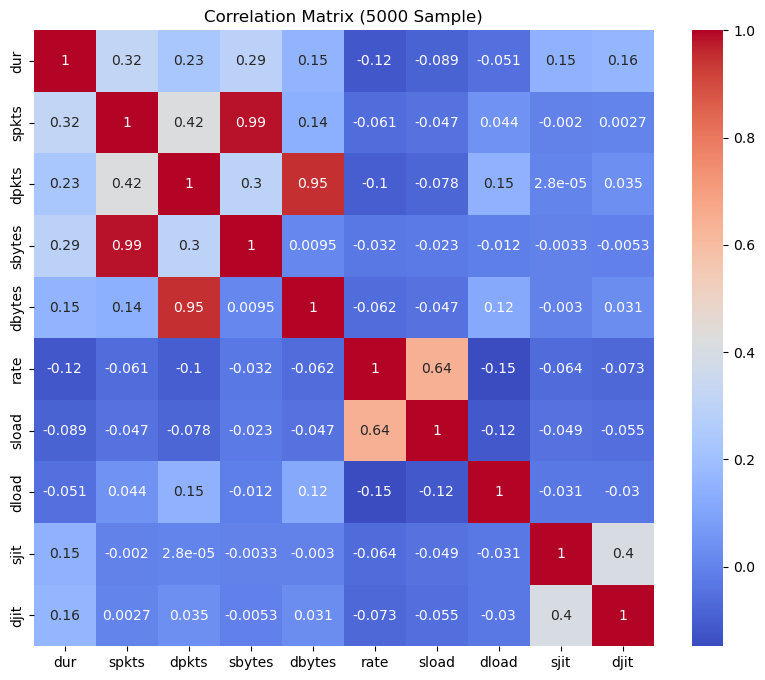

In [29]:
sample_df = df_train.sample(5000, random_state=42)
cols = [
    'dur',
    'spkts',
    'dpkts',
    'sbytes',
    'dbytes',
    'rate',
    'sload',
    'dload',
    'sjit',
    'djit'
]

plt.figure(figsize=(10, 8))
sns.heatmap(sample_df[cols].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix (5000 Sample)")
plt.show()

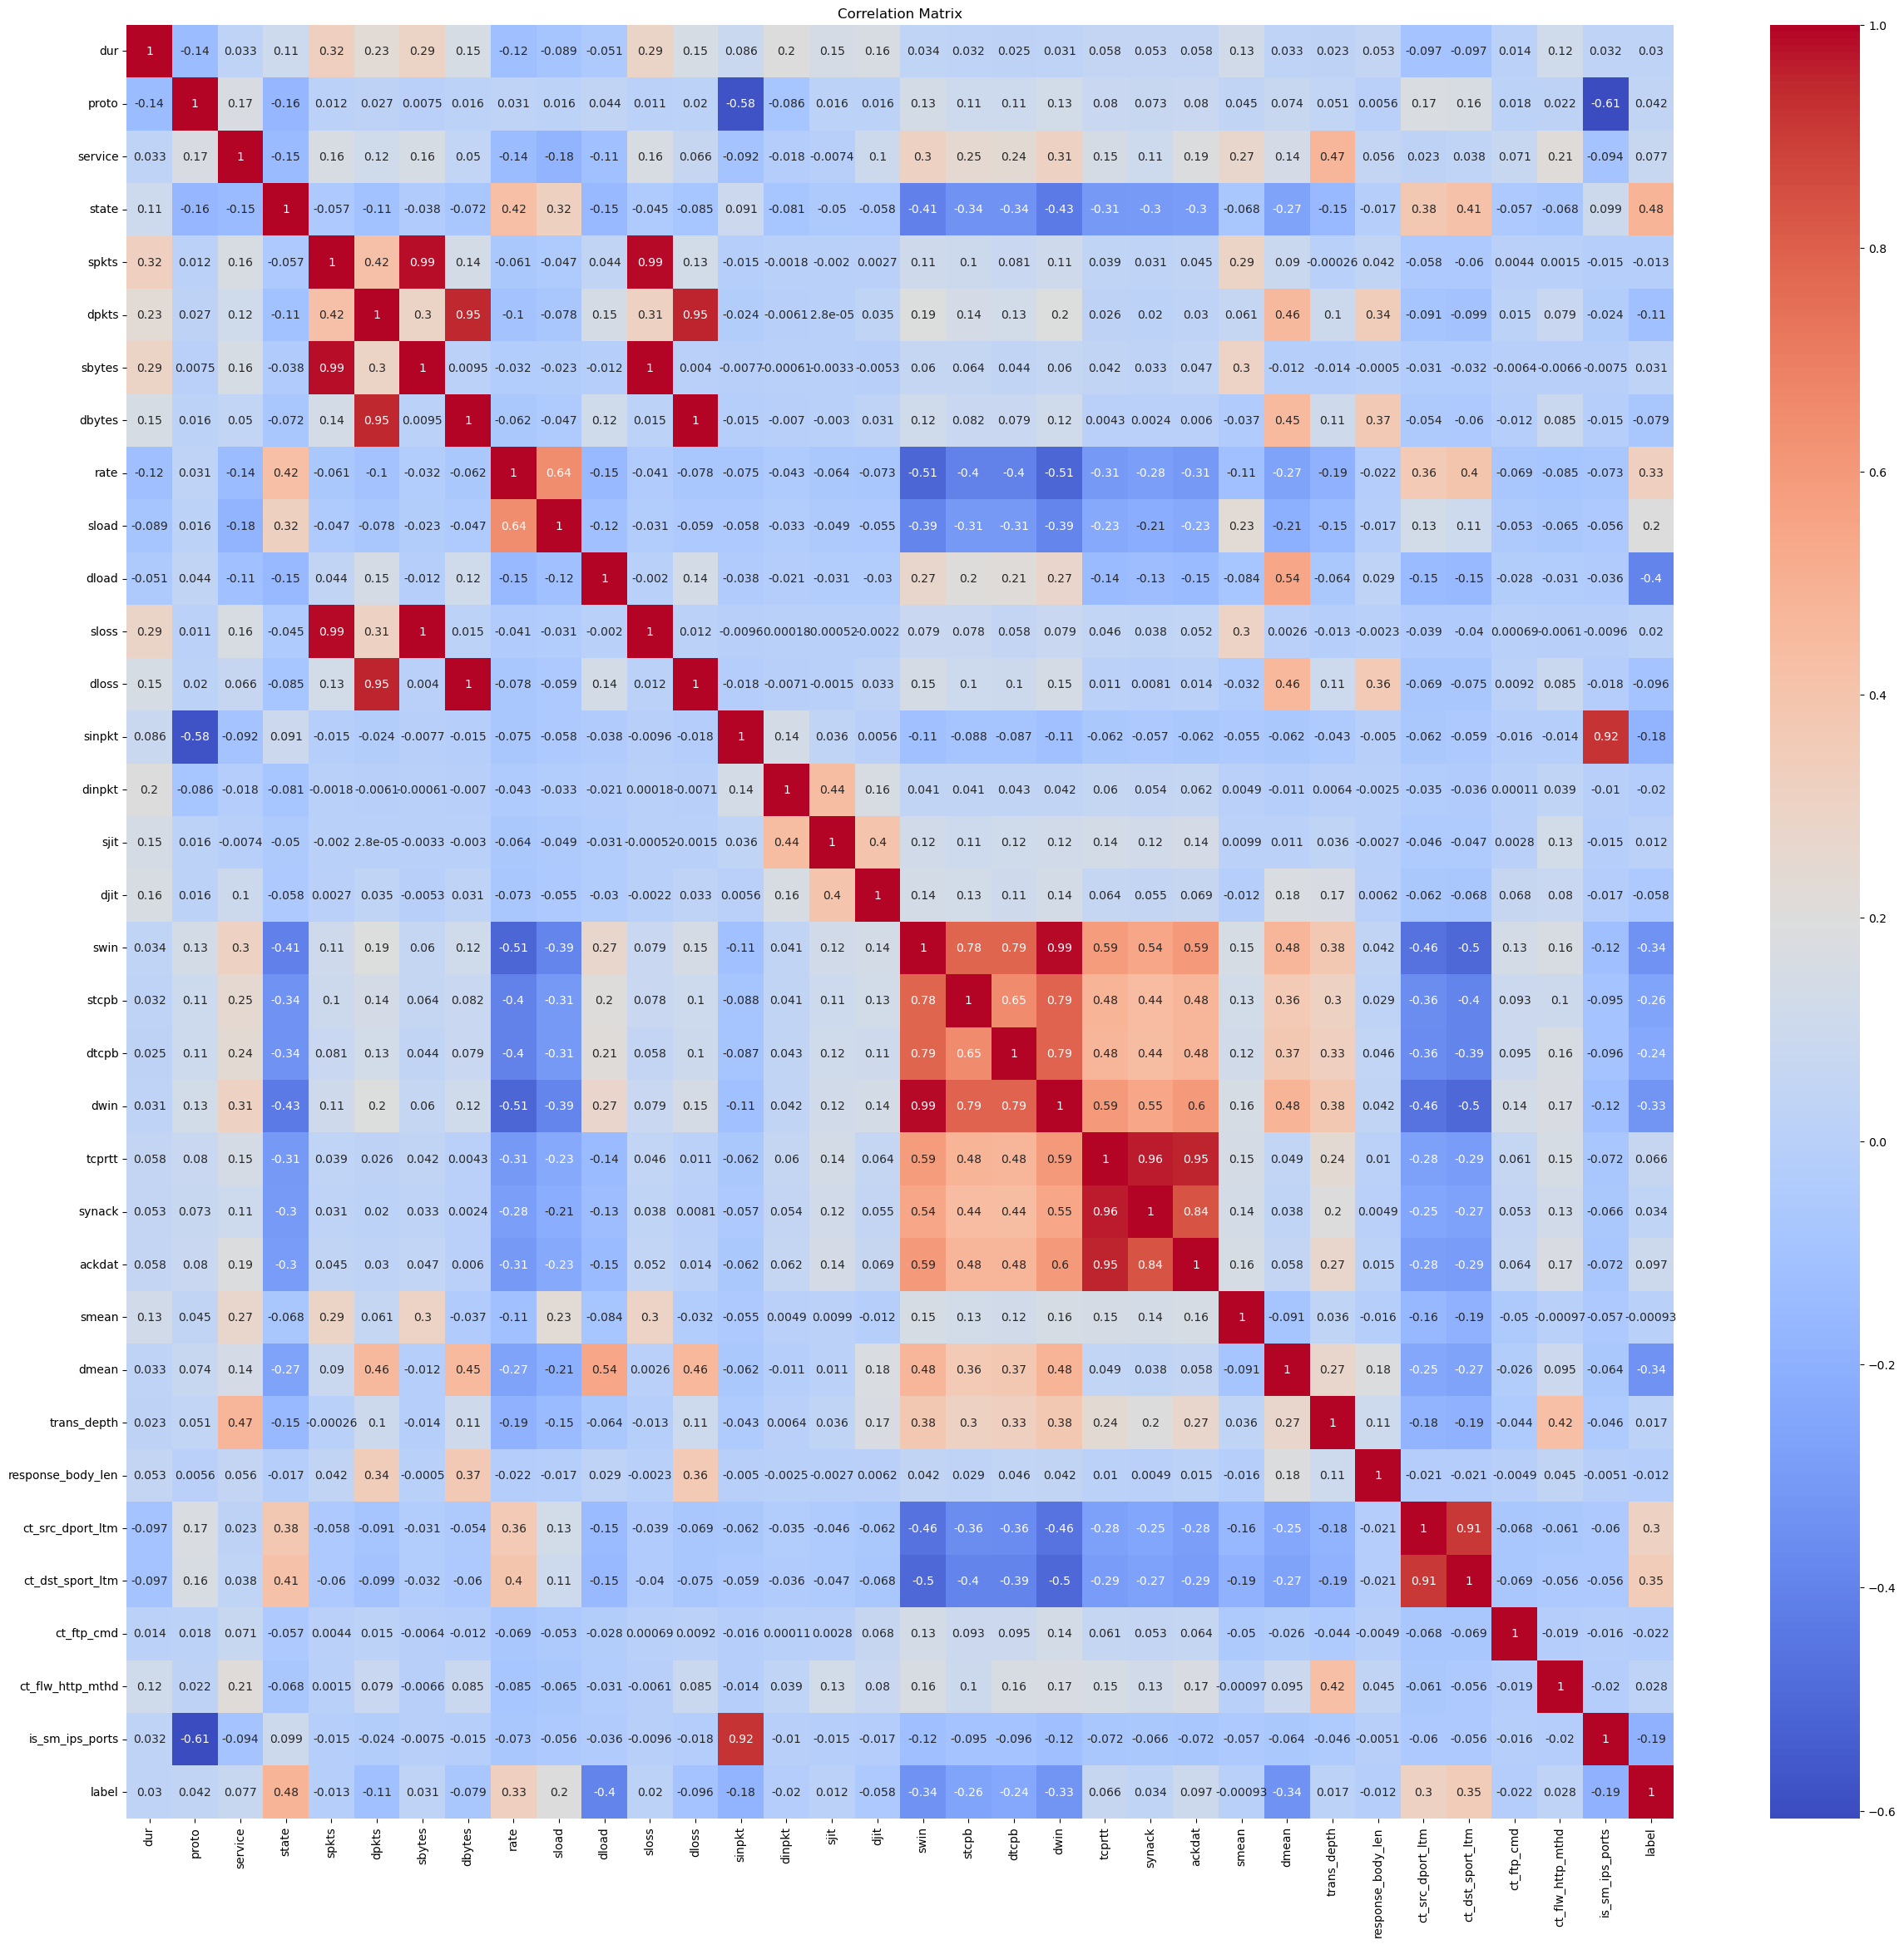

In [30]:
plt.figure(figsize=(30, 28))
sns.heatmap(sample_df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [40]:
def correlation(dataset, threshold):
    correlated_features = set()
    corr_matrix = df_train.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold:
                col_name = corr_matrix.columns[i]
                correlated_features.add(col_name)
    return correlated_features

In [42]:
correlation(df_train,0.95)

{'dbytes', 'dloss', 'dwin', 'sbytes', 'sloss'}

In [43]:
df_train.drop(['dbytes', 'dloss', 'dwin', 'sbytes', 'sloss'],axis=1,inplace=True)

In [44]:
df_train

,dur,proto,service,state,spkts,dpkts,rate,sload,dload,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,label
0,0.121478,113,0,2,6,4,74.087486,1.415894e+04,8495.365234,24.295601,8.375000,30.177547,11.830604,255,621772692,2202533631,0.000000,0.000000,0.000000,43,43,0,0,1,1,0,0,0,0
1,0.649902,113,0,2,14,38,78.473373,8.395112e+03,503571.312500,49.915001,15.432865,61.426933,1387.778320,255,1417884146,3077387971,0.000000,0.000000,0.000000,52,1106,0,0,1,1,0,0,0,0
2,1.623129,113,0,2,8,16,14.170161,1.572272e+03,60929.230469,231.875565,102.737206,17179.585938,11420.925781,255,2116150707,2963114973,0.111897,0.061458,0.050439,46,824,0,0,1,1,0,0,0,0
3,1.681642,113,3,2,12,12,13.677108,2.740179e+03,3358.622070,152.876541,90.235725,259.080170,4991.784668,255,1107119177,1047442890,0.000000,0.000000,0.000000,52,64,0,0,1,1,1,0,0,0
4,0.449454,113,0,2,10,6,33.373825,8.561499e+03,3987.059814,47.750332,75.659599,2415.837646,115.806999,255,2436137549,1977154190,0.128381,0.071147,0.057234,53,45,0,0,2,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175336,0.000009,119,2,3,2,0,111111.109375,5.066666e+07,0.000000,0.009000,0.000000,0.000000,0.000000,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,24,13,0,0,0,1
175337,0.505762,113,0,2,10,8,33.612648,8.826286e+03,4903.492188,54.400112,66.980568,3721.068848,120.177727,255,3518776216,3453092386,0.099440,0.036895,0.062545,62,44,0,0,1,1,0,0,0,1
175338,0.000009,119,2,3,2,0,111111.109375,5.066666e+07,0.000000,0.009000,0.000000,0.000000,0.000000,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,3,3,0,0,0,1
175339,0.000009,119,2,3,2,0,111111.109375,5.066666e+07,0.000000,0.009000,0.000000,0.000000,0.000000,0,0,0,0.000000,0.000000,0.000000,57,0,0,0,30,14,0,0,0,1
